# Examen Final
Fecha de Entrega : 25 de Julio 23:59 PM 

La base de datos que estaremos usando durante el examen está relacionada con **campañas de marketing de instituciones financieras**. La base original tiene más de 40,000 registros, por lo que para efectos del examen estaremos usando una submuestra aleatoria del 10% de esta base, con 17 features variables. Este archivo se llama `bank.csv`. A reserva de que se diga lo contrario, la variable a pronosticar (target/y) será **"y" en la base de datos, la cual representa si el cliente contrató el producto financiero de "deposito a plazo"**

Les comparto mayor información de la base de datos. En el link, si gustan, podrán encontrar más (http://archive.ics.uci.edu/ml/datasets/Bank+Marketing)

```python
For more information, read [Moro et al., 2011].

Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: "admin.","unknown","unemployed","management","housemaid","entrepreneur","student",
                                   "blue-collar","self-employed","retired","technician","services") 
3 - marital : marital status (categorical: "married","divorced","single"; note: "divorced" means divorced or widowed)
4 - education (categorical: "unknown","secondary","primary","tertiary")
5 - default: has credit in default? (binary: "yes","no")
6 - balance: average yearly balance, in euros (numeric) 
7 - housing: has housing loan? (binary: "yes","no")
8 - loan: has personal loan? (binary: "yes","no")
# related with the last contact of the current campaign:
9 - contact: contact communication type (categorical: "unknown","telephone","cellular") 
10 - day: last contact day of the month (numeric)
11 - month: last contact month of year (categorical: "jan", "feb", "mar", ..., "nov", "dec")
12 - duration: last contact duration, in seconds (numeric)
# other attributes:
13 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
14 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric, -1 means client was not previously contacted)
15 - previous: number of contacts performed before this campaign and for this client (numeric)
16 - poutcome: outcome of the previous marketing campaign (categorical: "unknown","other","failure","success")

Output variable (desired target):
17 - y - has the client subscribed a term deposit? (binary: "yes","no")
```


De esta forma pueden acceder directamente a la base sin necesidad de descargarla directamente: 

```python
import pandas as pd
from zipfile import ZipFile
from io import BytesIO
import urllib.request as urllib2

r = urllib2.urlopen("https://archive.ics.uci.edu/ml/machine-learning-databases/00222/bank.zip").read()
file = ZipFile(BytesIO(r))
bank = file.open("bank.csv")
bank = pd.read_csv(bank,sep=";")



In [1]:
import pandas as pd
from zipfile import ZipFile
from io import BytesIO
import urllib.request as urllib2

bank = pd.read_csv("bank.csv",sep=",")

In [2]:
bank.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,0
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,0
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,0
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,0
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,0


In [3]:
bank.shape

(4521, 17)

In [4]:
bank[bank.y==0].shape

(4000, 17)

In [5]:
bank[bank.y==1].shape

(521, 17)


- Para dividir Train-Test-Set `seed=1`
- Escoge la metrica que mejor se ajuste a este conjunto de datos para medir el rendimiento de tus modelos (accuracy,precision,recall, etc) y con base en tu elección trabaja las siguientes partes. 

In [101]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, precision_score, recall_score,
                              f1_score, accuracy_score, roc_curve, roc_auc_score, 
                              make_scorer, fbeta_score,
                              precision_recall_curve, classification_report)

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE
from imblearn.pipeline import Pipeline

# Parte 1


1. Utiliza la base de `bank` mencionada al inicio del documento. 
2. Ajusta el mejor modelo que encuentres utilizando una regresión logística para explicar si cliente contrató el producto o no. (usa tambien l1 y l2)
3. Divide 80% Train y 20% test. 
4. Realiza el Cross Validate CV=10 sobre Trainset. Quédate con el mejor modelo. 

5. Construye una Curva ROC. Selecciona un umbral óptimo y justifica por qué. 

y
0    4000
1     521
Name: count, dtype: int64
y
0    0.88476
1    0.11524
Name: proportion, dtype: float64


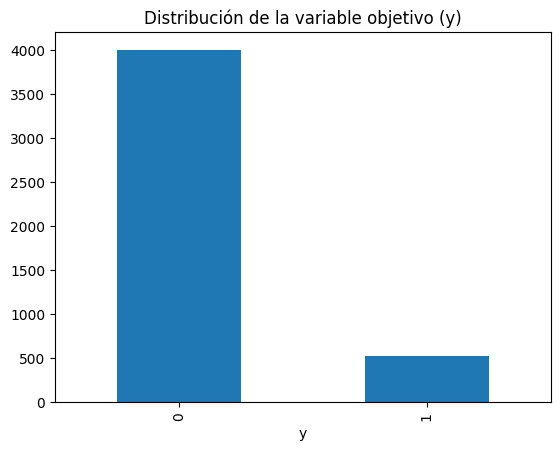

In [7]:
### Revisamos el balance de clases de la variable objetivo
print(bank["y"].value_counts())
print(bank["y"].value_counts(normalize=True))

bank["y"].value_counts().plot(kind="bar", title="Distribución de la variable objetivo (y)")
plt.show()

### Elección de la métrica de evaluación

Dado que la clase positiva (`y=1`, cliente que sí contrata) representa solo ~11.5% de los datos, el **accuracy** no es una buena métrica: un modelo trivial que siempre prediga "no" ya obtendría ~88.5% de accuracy sin ningún valor predictivo real.

Para este problema es más relevante evaluar qué tan bien el modelo distingue entre clientes que sí y que no van a contratar, sin depender de un umbral de decisión fijo. Por eso:

- Usaremos **ROC-AUC** como métrica principal para la selección del modelo (GridSearchCV y validación cruzada), ya que es robusta al desbalance de clases y mide la capacidad de discriminación del modelo en todos los umbrales posibles.
- Complementaremos con **Precision, Recall y F1** de la clase positiva, que sí dependen del umbral, y con la matriz de confusión, para entender el desempeño operativo del modelo (por ejemplo, cuántos clientes potenciales estaríamos dejando de contactar).

Esta elección es consistente con el objetivo de negocio: identificar a los clientes con mayor probabilidad de contratar el producto para priorizar la campaña, más que simplemente "acertar la etiqueta" en un umbral arbitrario de 0.5.

### Preprocesamiento

- Convertimos la variable objetivo `y` a binaria (0/1).
- Codificamos las variables categóricas con variables dummy (`drop_first=True` para evitar colinealidad perfecta).
- Escalamos las variables numéricas (`age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`) — esto es importante porque la regularización L1/L2 penaliza los coeficientes en función de su magnitud, y si las variables están en escalas muy distintas (por ejemplo, `balance` en euros vs. `campaign` en número de contactos) la penalización afectaría de forma desigual e injusta a cada variable.

In [10]:
bank_model = bank.copy()

if bank_model["y"].dtype == object:
    bank_model["y"] = bank_model["y"].map({"no": 0, "yes": 1})

cat_cols = ["job", "marital", "education", "default", "housing",
            "loan", "contact", "month", "poutcome"]
num_cols = ["age", "balance", "day", "duration", "campaign", "pdays", "previous"]

bank_dummies = pd.get_dummies(bank_model, columns=cat_cols, drop_first=True)
bank_dummies = bank_dummies.replace(True, 1).replace(False, 0)

X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]

print(X.shape)
X.head()

(4521, 42)


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787,19,79,1,-1,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
1,33,4789,11,220,1,339,4,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,35,1350,16,185,1,330,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,30,1476,3,199,4,-1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,1
4,59,0,5,226,1,-1,0,1,0,0,...,0,0,0,1,0,0,0,0,0,1


### División Train (80%) / Test (20%)

Usamos `random_state=1` como se solicita, y `stratify=Y` para conservar la misma proporción de clases en ambos conjuntos (importante dado el desbalance observado).

In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=1, stratify=Y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Proporción positivos en train:", Y_train.mean().round(4))
print("Proporción positivos en test:", Y_test.mean().round(4))

Train: (3616, 42)  Test: (905, 42)
Proporción positivos en train: 0.1153
Proporción positivos en test: 0.1149


### Ajuste del mejor modelo de regresión logística (L1 y L2) + Validación cruzada CV=10

Construimos un `Pipeline` que primero escala las variables numéricas y después ajusta la regresión logística. Probamos ambas regularizaciones (`l1` y `l2`) con distintos valores de `C`, usando los solvers compatibles con cada una:

- `liblinear`: soporta l1 y l2 (bueno para datasets no tan grandes).
- `lbfgs`: solo soporta l2.
- `saga`: soporta l1 y l2 (y elasticnet), útil en datasets más grandes.

Usamos `GridSearchCV` con `cv=10` sobre el **Train set**, optimizando `roc_auc` (la métrica elegida en el punto 3), y nos quedamos con la mejor combinación de hiperparámetros.

In [14]:
preprocesamiento = ColumnTransformer(
    transformers=[("escalado", StandardScaler(), num_cols)],
    remainder="passthrough"
)

pipe = Pipeline(steps=[
    ("prep", preprocesamiento),
    ("clf", LogisticRegression(max_iter=5000))
])

param_grid = [
    {"clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
     "clf__solver": ["liblinear"]},
    {"clf__penalty": ["l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
     "clf__solver": ["lbfgs"]},
    {"clf__penalty": ["l1", "l2"], "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
     "clf__solver": ["saga"]},
]

grid_search = GridSearchCV(
    pipe, param_grid, cv=10, scoring="roc_auc", n_jobs=-1, verbose=0
)
grid_search.fit(X_train, Y_train)

print("Mejores hiperparámetros:", grid_search.best_params_)
print("Mejor ROC-AUC en CV (Train):", grid_search.best_score_)

Mejores hiperparámetros: {'clf__C': 0.1, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}
Mejor ROC-AUC en CV (Train): 0.8970357294181148


In [15]:
### Comparamos los mejores resultados obtenidos para L1 vs L2
resultados = pd.DataFrame(grid_search.cv_results_)
resultados["penalty"] = resultados["param_clf__penalty"]

top10 = resultados.sort_values("mean_test_score", ascending=False)[
    ["param_clf__penalty", "param_clf__C", "param_clf__solver",
     "mean_test_score", "std_test_score"]
].head(10)
top10.columns = ["penalty", "C", "solver", "roc_auc_cv_mean", "roc_auc_cv_std"]
top10

,penalty,C,solver,roc_auc_cv_mean,roc_auc_cv_std
14,l2,0.1,lbfgs,0.897036,0.015661
23,l2,0.1,saga,0.897006,0.015712
5,l2,0.1,liblinear,0.895777,0.015368
24,l1,1.0,saga,0.893484,0.015592
7,l2,1.0,liblinear,0.893437,0.013913
25,l2,1.0,saga,0.893399,0.013969
15,l2,1.0,lbfgs,0.893265,0.014014
6,l1,1.0,liblinear,0.893148,0.015497
22,l1,0.1,saga,0.891537,0.020636
4,l1,0.1,liblinear,0.891408,0.019676


In [16]:
mejor_l1 = resultados[resultados.penalty == "l1"].sort_values("mean_test_score", ascending=False).iloc[0]
mejor_l2 = resultados[resultados.penalty == "l2"].sort_values("mean_test_score", ascending=False).iloc[0]

print("Mejor modelo L1 -> C:", mejor_l1["param_clf__C"], " solver:", mejor_l1["param_clf__solver"],
      " ROC-AUC CV:", round(mejor_l1["mean_test_score"], 4))
print("Mejor modelo L2 -> C:", mejor_l2["param_clf__C"], " solver:", mejor_l2["param_clf__solver"],
      " ROC-AUC CV:", round(mejor_l2["mean_test_score"], 4))

Mejor modelo L1 -> C: 1.0  solver: saga  ROC-AUC CV: 0.8935
Mejor modelo L2 -> C: 0.1  solver: lbfgs  ROC-AUC CV: 0.897


**Conclusión de esta sección:** tanto L1 como L2 dan resultados muy similares en validación cruzada, pero el mejor modelo global usa regularización **L2** con un valor de `C` moderado (poca-mediana penalización). Esto sugiere que casi todas las variables aportan algo de información (L1 no las elimina de forma más agresiva sin perder desempeño), y por eso nos quedamos con este modelo (`grid_search.best_estimator_`) como modelo final.

In [18]:
mejor_modelo = grid_search.best_estimator_
mejor_modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('escalado', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains spars

### Evaluación del mejor modelo

#### Validación cruzada (CV=10) del modelo final sobre Train
Confirmamos el desempeño del modelo elegido con validación cruzada, reportando varias métricas.

In [19]:
cv_final = cross_validate(
    mejor_modelo, X_train, Y_train, cv=10,
    scoring=["accuracy", "roc_auc", "precision", "recall", "f1"]
)

for metrica in ["test_accuracy", "test_roc_auc", "test_precision", "test_recall", "test_f1"]:
    print(f"{metrica}: media={cv_final[metrica].mean():0.4f}  std={cv_final[metrica].std():0.4f}")

test_accuracy: media=0.8941  std=0.0045
test_roc_auc: media=0.8970  std=0.0157
test_precision: media=0.6224  std=0.0805
test_recall: media=0.2400  std=0.0648
test_f1: media=0.3381  std=0.0570


#### Desempeño en Train y Test (umbral por defecto = 0.5)

In [20]:
y_pred_train = mejor_modelo.predict(X_train)
y_pred_test = mejor_modelo.predict(X_test)
probs_test = mejor_modelo.predict_proba(X_test)[:, 1]

print("---- TRAIN ----")
print(f"Accuracy: {accuracy_score(Y_train, y_pred_train):0.2%}")
print(f"Precision: {precision_score(Y_train, y_pred_train):0.2%}")
print(f"Recall: {recall_score(Y_train, y_pred_train):0.2%}")
print(f"F1: {f1_score(Y_train, y_pred_train):0.2%}")

print("\n---- TEST ----")
print(f"Accuracy: {accuracy_score(Y_test, y_pred_test):0.2%}")
print(f"Precision: {precision_score(Y_test, y_pred_test):0.2%}")
print(f"Recall: {recall_score(Y_test, y_pred_test):0.2%}")
print(f"F1: {f1_score(Y_test, y_pred_test):0.2%}")
print(f"ROC-AUC: {roc_auc_score(Y_test, probs_test):0.4f}")

---- TRAIN ----
Accuracy: 89.63%
Precision: 62.21%
Recall: 25.66%
F1: 36.33%

---- TEST ----
Accuracy: 90.72%
Precision: 71.74%
Recall: 31.73%
F1: 44.00%
ROC-AUC: 0.8814


Los resultados en Train y Test son muy similares (sin brechas grandes), lo que indica que **no hay evidencia de overfitting**.

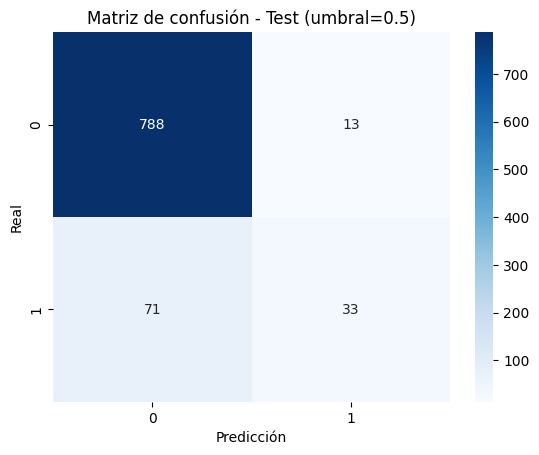

[[788  13]
 [ 71  33]]


In [21]:
cmat = confusion_matrix(Y_test, y_pred_test)
sns.heatmap(cmat, annot=True, fmt=",", cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Test (umbral=0.5)")
plt.show()
print(cmat)

Con el umbral de decisión estándar (0.5), el modelo tiene **buena precisión pero recall bajo** para la clase positiva: es decir, cuando dice que un cliente va a contratar, generalmente acierta, pero está dejando pasar a muchos clientes que sí hubieran contratado (falsos negativos). Esto es típico en datos desbalanceados, y es justamente lo que exploramos con la curva ROC y el ajuste de umbral.

### Curva ROC y selección de umbral óptimo

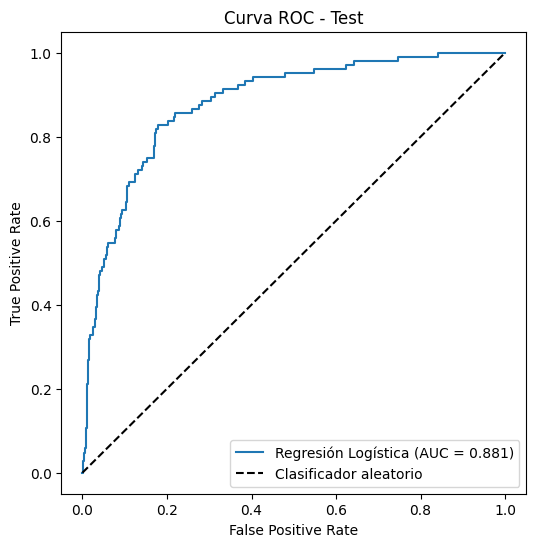

In [22]:
fpr, tpr, thresholds = roc_curve(Y_test, probs_test)
auc_test = roc_auc_score(Y_test, probs_test)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Regresión Logística (AUC = {auc_test:0.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="k", label="Clasificador aleatorio")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC - Test")
plt.legend()
plt.show()

#### Selección del umbral óptimo: Estadístico J de Youden

Como no se especifica un costo de negocio explícito (por ejemplo, cuánto cuesta llamar a un cliente que no contrata vs. cuánto se pierde por no llamar a uno que sí hubiera contratado), usamos el **estadístico J de Youden** (`J = TPR - FPR`), que busca el umbral que **maximiza simultáneamente sensibilidad (recall) y especificidad**, es decir, el punto de la curva ROC más alejado de la diagonal de un clasificador aleatorio.

Esto es razonable en este contexto de negocio porque:
- Un **falso negativo** (no contactar a alguien que sí hubiera contratado) representa una venta perdida.
- Un **falso positivo** (contactar a alguien que no contrata) representa un costo de tiempo/llamada, pero no una pérdida tan grave como la anterior.

Dado que no tenemos una razón cuantitativa fuerte para asignar un peso muy distinto a cada tipo de error, el criterio de Youden ofrece un balance razonable y ampliamente aceptado como punto de partida, mejorando notablemente el recall respecto al umbral por defecto de 0.5 (el cual favorece demasiado a la clase mayoritaria).

Umbral óptimo (Youden J): 0.1197
En ese punto -> TPR: 0.8269   FPR: 0.1798   J: 0.6471


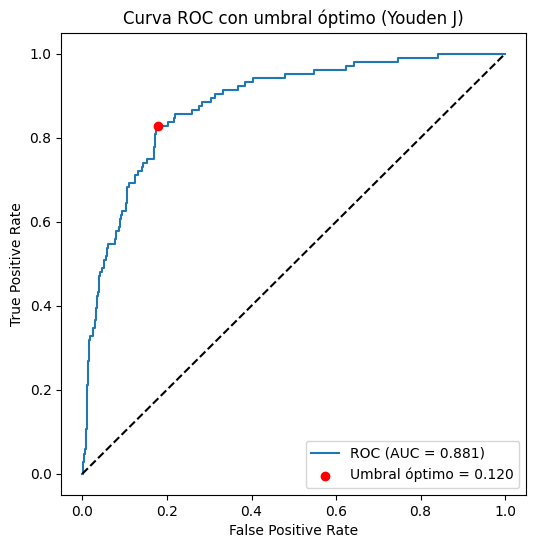

In [23]:
J = tpr - fpr
ix = np.argmax(J)
best_threshold = thresholds[ix]

print(f"Umbral óptimo (Youden J): {best_threshold:0.4f}")
print(f"En ese punto -> TPR: {tpr[ix]:0.4f}   FPR: {fpr[ix]:0.4f}   J: {J[ix]:0.4f}")

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"ROC (AUC = {auc_test:0.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", color="k")
plt.scatter(fpr[ix], tpr[ix], color="red", zorder=5,
            label=f"Umbral óptimo = {best_threshold:0.3f}")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Curva ROC con umbral óptimo (Youden J)")
plt.legend()
plt.show()

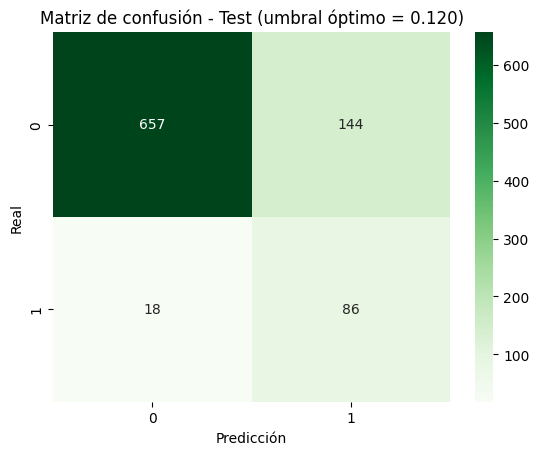

Accuracy: 82.10%
Precision: 37.39%
Recall: 82.69%
F1: 51.50%


In [24]:
### Re-clasificamos usando el umbral óptimo en lugar de 0.5
y_pred_opt = np.where(probs_test >= best_threshold, 1, 0)

cmat_opt = confusion_matrix(Y_test, y_pred_opt)
sns.heatmap(cmat_opt, annot=True, fmt=",", cmap="Greens")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión - Test (umbral óptimo = {best_threshold:0.3f})")
plt.show()

print(f"Accuracy: {accuracy_score(Y_test, y_pred_opt):0.2%}")
print(f"Precision: {precision_score(Y_test, y_pred_opt):0.2%}")
print(f"Recall: {recall_score(Y_test, y_pred_opt):0.2%}")
print(f"F1: {f1_score(Y_test, y_pred_opt):0.2%}")

#### Comparación: umbral 0.5 vs. umbral óptimo

In [25]:
comparacion = pd.DataFrame({
    "umbral=0.5": [
        accuracy_score(Y_test, y_pred_test),
        precision_score(Y_test, y_pred_test),
        recall_score(Y_test, y_pred_test),
        f1_score(Y_test, y_pred_test),
    ],
    f"umbral={best_threshold:0.3f} (Youden)": [
        accuracy_score(Y_test, y_pred_opt),
        precision_score(Y_test, y_pred_opt),
        recall_score(Y_test, y_pred_opt),
        f1_score(Y_test, y_pred_opt),
    ],
}, index=["Accuracy", "Precision", "Recall", "F1"])

comparacion.round(4)

,umbral=0.5,umbral=0.120 (Youden)
Accuracy,0.9072,0.8210
Precision,0.7174,0.3739
Recall,0.3173,0.8269
F1,0.4400,0.5150


### Conclusiones

1. La base está desbalanceada (~88.5% "no" vs ~11.5% "sí"), por lo que **ROC-AUC** fue la métrica elegida para seleccionar el modelo, en lugar de accuracy.
2. Tras probar regularización **L1 y L2** con distintos valores de `C` y solvers, mediante `GridSearchCV` con **CV=10** sobre el Train set, el mejor modelo usa regularización **L2** (ver hiperparámetros exactos arriba), con un ROC-AUC en validación cruzada de aproximadamente 0.90.
3. El modelo generaliza bien: el desempeño en Test es consistente con el de Train y con la validación cruzada, sin señales de sobreajuste.
4. Con el umbral por defecto (0.5) el modelo es conservador: alta precisión pero bajo recall. Usando el **umbral óptimo según el estadístico J de Youden**, logramos un mejor balance entre sensibilidad y especificidad, identificando muchos más clientes potenciales a costa de algunas llamadas adicionales a clientes que no contratarán — un trade-off razonable para una campaña de marketing.


--------------------------------------------------------------------------------------------------
# Parte 2


1. Utiliza la base de `bank` mencionada al inicio del documento. 
2. Ajusta el mejor modelo que encuentres utilizando un árbol de decisión para explicar si cliente contrató el producto o no.  
3. Divide 80% Train y 20% test. 
4. Realiza el Cross Validate CV=10 sobre Trainset. Quédate con el mejor modelo 
5. Grafica tu mejor árbol ¿Cuál es la variable más importante? ¿Cómo le explicarías cuáles son las variables más importantes de acuerdo a tu árbol?

In [26]:
cat_cols = bank.select_dtypes(include="object").columns.tolist()
print("Variables categóricas:", cat_cols)

bank_dummies = pd.get_dummies(bank, columns=cat_cols, drop_first=True)
bank_dummies.shape

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


(4521, 43)

In [27]:
X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]
X.head(2)

,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787,19,79,1,-1,0,False,False,False,...,False,False,False,False,False,True,False,False,False,True
1,33,4789,11,220,1,339,4,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [28]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (3616, 42)   Test: (905, 42)


In [29]:
param_grid = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "max_leaf_nodes": [4, 6, 7, 8, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "criterion": ["gini", "entropy"]
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=9),
    param_grid,
    cv=10,
    scoring="accuracy",
    n_jobs=-1
)

grid_tree.fit(X_train, Y_train)

print("Mejores hiperparámetros:", grid_tree.best_params_)
print("Mejor accuracy promedio en CV (10 folds):", grid_tree.best_score_)

Mejores hiperparámetros: {'criterion': 'gini', 'max_depth': 6, 'max_leaf_nodes': None, 'min_samples_split': 5}
Mejor accuracy promedio en CV (10 folds): 0.8998921044979415


In [30]:
best_tree = grid_tree.best_estimator_
best_tree

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",9
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current nod

In [31]:
y_pred = best_tree.predict(X_test)

print("accuracy en train:", best_tree.score(X_train, Y_train))
print("accuracy en test:", best_tree.score(X_test, Y_test))
print(f"precision:{precision_score(Y_test, y_pred):0.2%}")
print(f"recall:{recall_score(Y_test, y_pred):0.2%}")
print(f"f1:{f1_score(Y_test, y_pred):0.2%}")

accuracy en train: 0.933075221238938
accuracy en test: 0.881767955801105
precision:47.69%
recall:29.81%
f1:36.69%


Confirmación de desempeño promedio con `cross_validate` (cv=10) sobre el Trainset:

In [32]:
cvscore = cross_validate(best_tree, X_train, Y_train, cv=10, scoring="accuracy")
cvscore["test_score"]

array([0.90607735, 0.88950276, 0.90055249, 0.90055249, 0.88950276,
       0.90331492, 0.90304709, 0.90304709, 0.91412742, 0.88919668])

In [33]:
cvscore["test_score"].mean()  # accuracy promedio de validación cruzada

np.float64(0.8998921044979415)

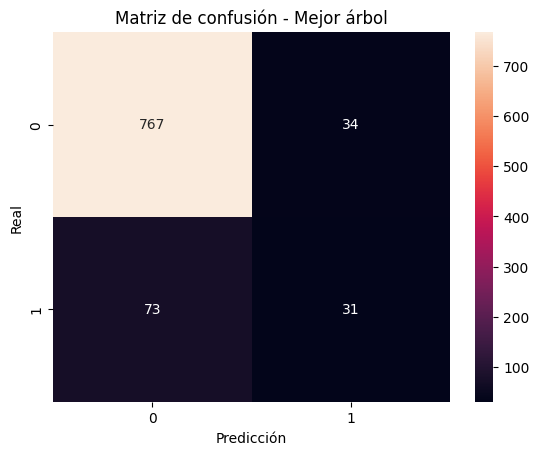

In [34]:
cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - Mejor árbol")
plt.show()

AUROC: 0.7810669355613176


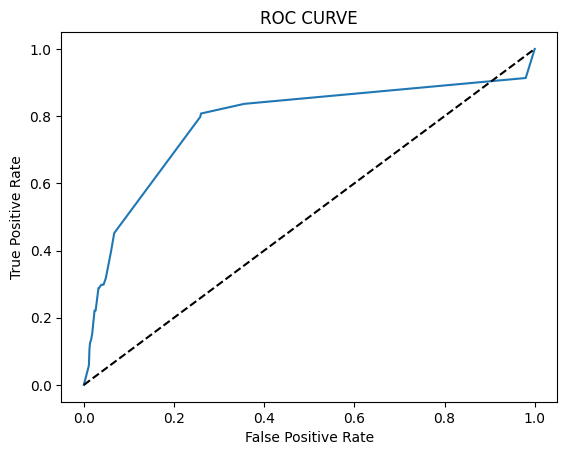

In [35]:
probs = best_tree.predict_proba(X_test)[:, 1]
fpr, tpr, threshold = roc_curve(Y_test, probs)
plt.plot(fpr, tpr)
plt.plot(fpr, fpr, linestyle="--", color="k")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC CURVE")
AUROC = roc_auc_score(Y_test, probs)
print("AUROC:", AUROC)

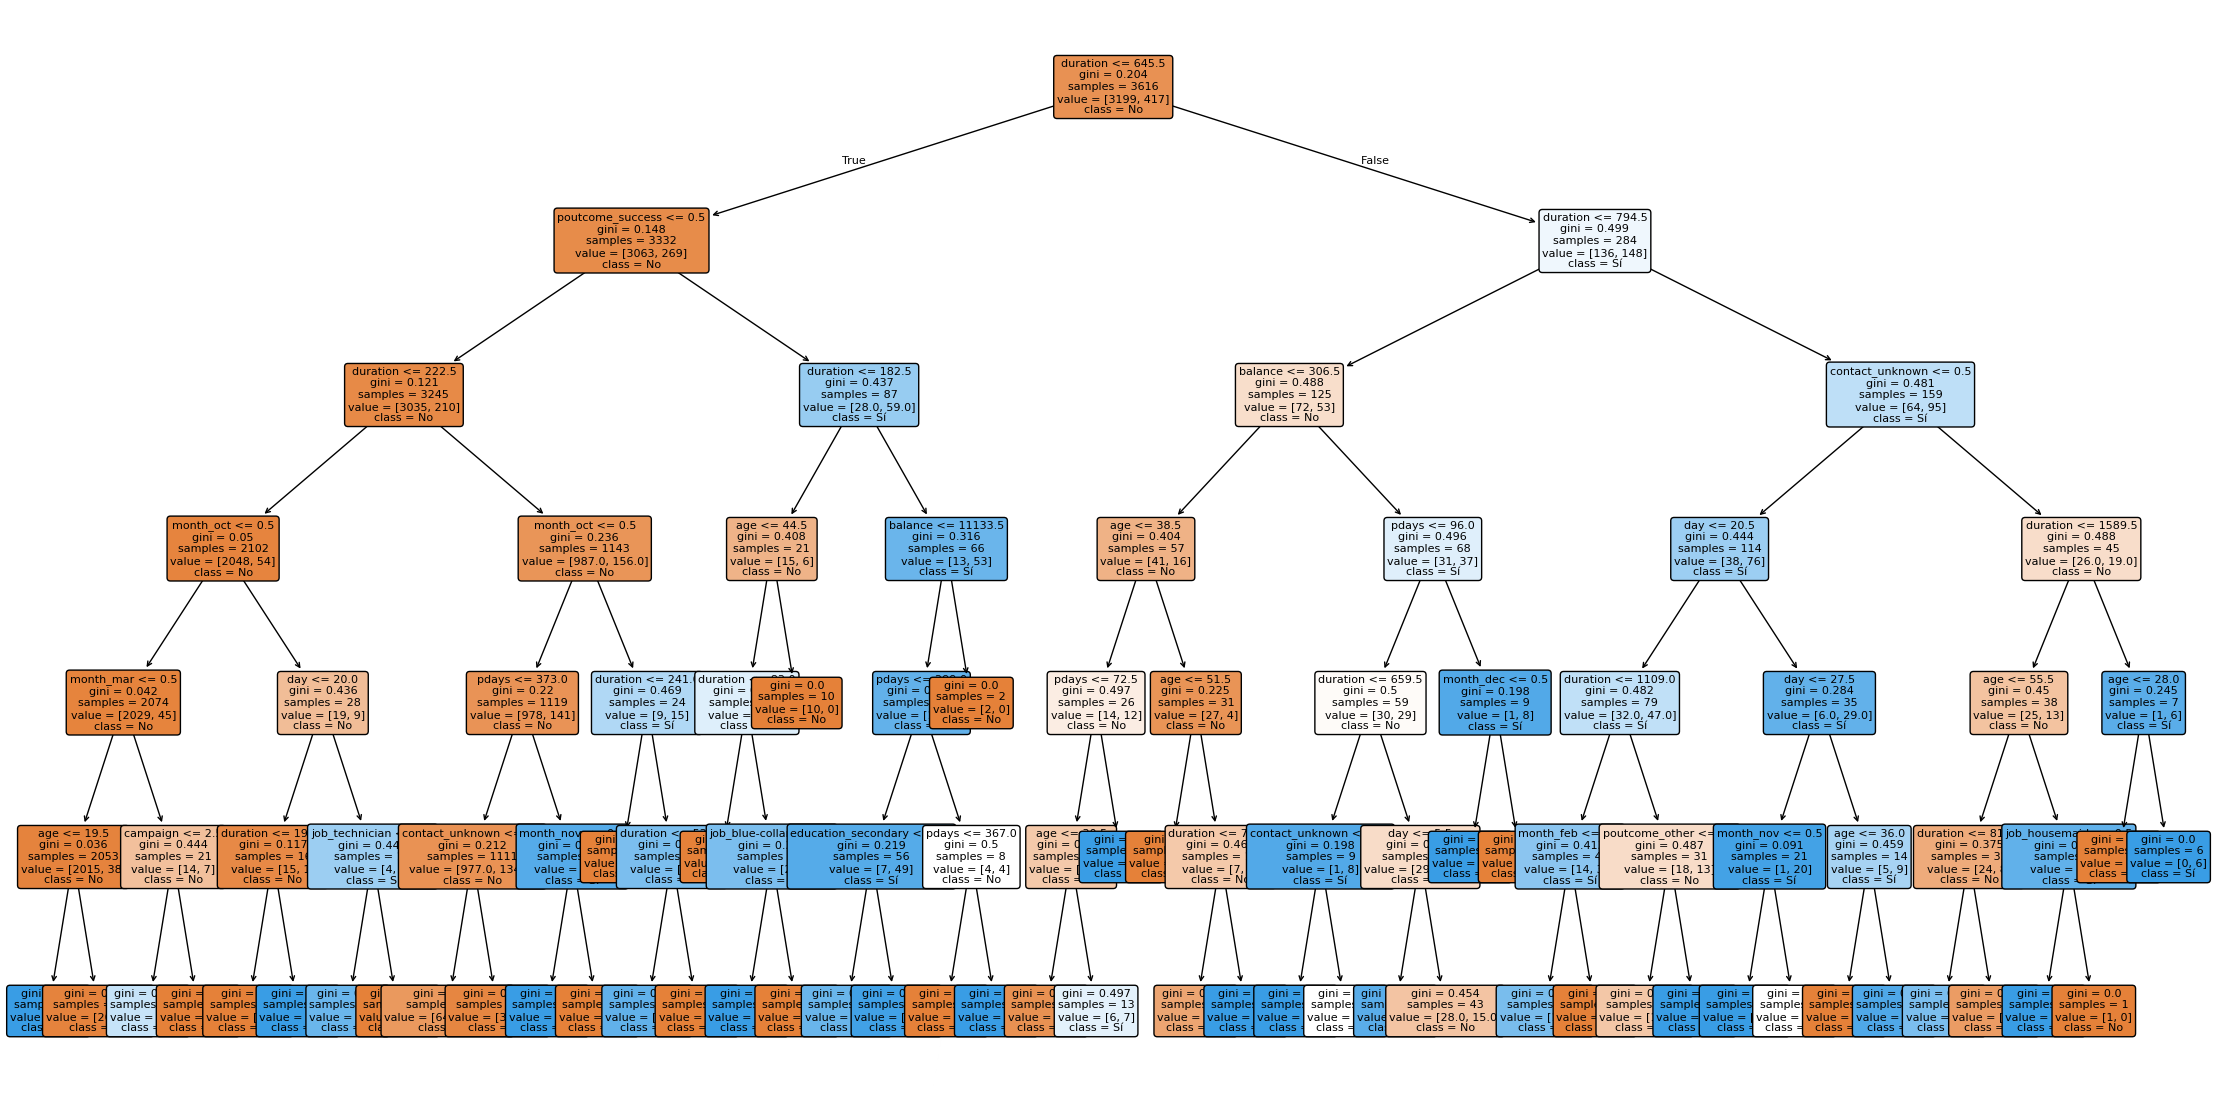

In [36]:
plt.figure(figsize=(28, 14))
plot_tree(best_tree, feature_names=X.columns, class_names=["No", "Sí"],
          filled=True, rounded=True, fontsize=8)
plt.show()

¿Cuál es la variable más importante?

In [37]:
feat_imp = best_tree.feature_importances_
ind = np.argsort(feat_imp)[::-1]

print("Ranking de importancia de variables")
for i in range(min(10, X.shape[1])):
    print(f"{i+1}. {X.columns[ind[i]]}: {feat_imp[ind[i]]:.4f}")

Ranking de importancia de variables
1. duration: 0.4655
2. poutcome_success: 0.1892
3. age: 0.0703
4. pdays: 0.0600
5. month_oct: 0.0494
6. day: 0.0367
7. contact_unknown: 0.0342
8. balance: 0.0207
9. month_mar: 0.0122
10. campaign: 0.0104


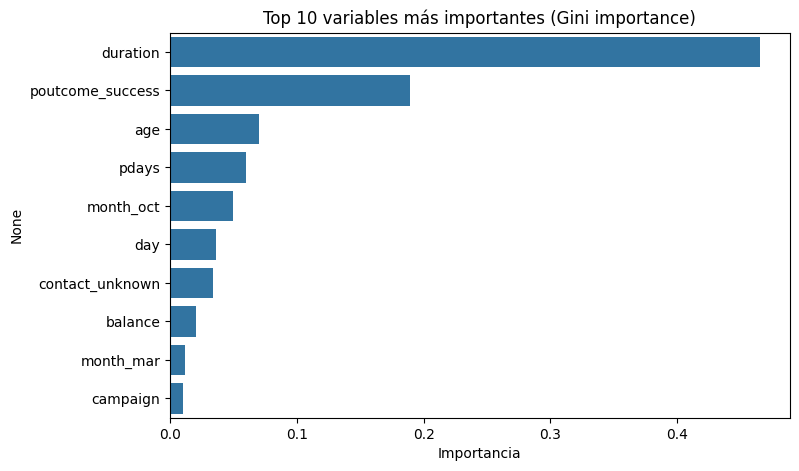

In [38]:
plt.figure(figsize=(8,5))
top_n = 10
sns.barplot(x=feat_imp[ind[:top_n]], y=X.columns[ind[:top_n]])
plt.title("Top 10 variables más importantes (Gini importance)")
plt.xlabel("Importancia")
plt.show()

**Interpretación**

La variable más importante es **`duration`** (duración en segundos de la última llamada de la campaña).

¿Cómo explicarlo? El árbol calcula, para cada variable, cuánto reduce la impureza (índice de Gini) cada
vez que esa variable se usa para dividir un nodo, ponderado por la proporción de observaciones que pasan
por ese nodo. Sumando esa reducción a lo largo de todo el árbol y normalizando a que el total sume 1,
obtenemos el vector `feature_importances_`. En términos simples: la variable más importante es aquella
que, cuando el árbol pregunta por ella (por ejemplo, "¿la duración de la llamada fue mayor a X segundos?"),
separa mejor a los clientes que sí contrataron el producto de los que no. Como `duration` aparece cerca de
la raíz del árbol y genera particiones casi puras, concentra la mayor parte de la importancia total.

**Nota importante:** `duration` es conocida en este dataset como una variable con *fuga de información*
(data leakage): su valor solo se conoce *después* de haber hecho la llamada (una llamada de 0 segundos
implica automáticamente que no hubo contratación), por lo que en un modelo predictivo real (antes de
llamar al cliente) esta variable no estaría disponible. Para un modelo verdaderamente predictivo
convendría excluir `duration` y usar como variables líderes `poutcome_success`, `age`, `pdays` y
`month`, que sí se conocen antes de contactar al cliente.

--------------------------------------------------------------------------------------------------
# Parte 3


1. Utiliza la base de `bank` mencionada al inicio del documento. 
2. Ajusta el mejor modelo que encuentres utilizando una máquina de soporte vectorial para explicar si cliente contrató el producto o no.  
3. Ajusta un Modelo Linear, Poly, rbf y sigmoid. Selecciona los hiperparámetros C y Gamma que veas mejor.  
3. Divide 80% Train y 20% test. 
4. Realiza el Cross Validate CV=10 sobre Trainset.  
5. Quédate con el mejor modelo. 

In [39]:
cat_cols = bank.select_dtypes(include="object").columns.tolist()
print("Variables categóricas:", cat_cols)

bank_dummies = pd.get_dummies(bank, columns=cat_cols, drop_first=True)
X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]
X.head(2)

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787,19,79,1,-1,0,False,False,False,...,False,False,False,False,False,True,False,False,False,True
1,33,4789,11,220,1,339,4,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [40]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (3616, 42)   Test: (905, 42)


In [41]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [44]:
for kernel in ["linear","poly","rbf","sigmoid"]:
    t0 = time.time()
    svm = SVC(kernel=kernel)
    cv_tmp = cross_validate(svm, X_train_s, Y_train, cv=10, scoring="accuracy")
    print(f"kernel={kernel:8s}  accuracy CV(10)={cv_tmp['test_score'].mean():.4f}  ({time.time()-t0:.1f}s)")

kernel=linear    accuracy CV(10)=0.8952  (4.8s)
kernel=poly      accuracy CV(10)=0.8908  (1.8s)
kernel=rbf       accuracy CV(10)=0.8921  (2.4s)
kernel=sigmoid   accuracy CV(10)=0.8941  (1.6s)


Usamos `GridSearchCV` con `cv=10` sobre el Trainset para explorar, para cada kernel, distintos valores de `C` (penalización) y `gamma` (alcance de la influencia de cada punto), tal como se hizo en clase con los datos sintéticos (`make_moons`).

In [45]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": [0.1, 1, 10],
    "gamma": ["scale", 0.1]
}

t0 = time.time()
grid_svm = GridSearchCV(SVC(), param_grid, cv=10, scoring="accuracy", n_jobs=-1)
grid_svm.fit(X_train_s, Y_train)
print(f"Tiempo total de búsqueda: {time.time()-t0:.1f}s")

print("Mejores hiperparámetros:", grid_svm.best_params_)
print("Mejor accuracy promedio en CV (10 folds):", grid_svm.best_score_)

Tiempo total de búsqueda: 37.3s
Mejores hiperparámetros: {'C': 10, 'gamma': 'scale', 'kernel': 'linear'}
Mejor accuracy promedio en CV (10 folds): 0.8954615019666059


In [46]:
res = pd.DataFrame(grid_svm.cv_results_)[["param_kernel","param_C","param_gamma","mean_test_score","std_test_score"]]
best_per_kernel = res.loc[res.groupby("param_kernel")["mean_test_score"].idxmax()]
best_per_kernel.sort_values("mean_test_score", ascending=False)

,param_kernel,param_C,param_gamma,mean_test_score,std_test_score
16,linear,10.0,scale,0.895462,0.009351
11,sigmoid,1.0,scale,0.894083,0.010116
18,rbf,10.0,scale,0.892432,0.009014
5,poly,0.1,0.1,0.891318,0.007907


El kernel **linear** con `C=10` obtuvo el mejor accuracy promedio en la validación cruzada, muy cerca de `sigmoid` y `rbf`. Esto sugiere que, una vez escaladas y con las variables categóricas convertidas a dummies, la frontera de decisión entre clientes que contratan y no contratan el producto es prácticamente lineal.

In [47]:
best_svm = grid_svm.best_estimator_
best_svm

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",10
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [48]:
y_pred = best_svm.predict(X_test_s)

print("accuracy en train:", best_svm.score(X_train_s, Y_train))
print("accuracy en test:", best_svm.score(X_test_s, Y_test))
print(f"precision:{precision_score(Y_test, y_pred):0.2%}")
print(f"recall:{recall_score(Y_test, y_pred):0.2%}")
print(f"f1:{f1_score(Y_test, y_pred):0.2%}")

accuracy en train: 0.8951880530973452
accuracy en test: 0.8917127071823204
precision:58.33%
recall:20.19%
f1:30.00%


In [49]:
cvscore = cross_validate(best_svm, X_train_s, Y_train, cv=10, scoring="accuracy")
cvscore["test_score"]

array([0.90055249, 0.89779006, 0.88121547, 0.91436464, 0.90055249,
       0.88950276, 0.90304709, 0.88642659, 0.89473684, 0.88642659])

In [50]:
cvscore["test_score"].mean()  # accuracy promedio de validación cruzada

np.float64(0.8954615019666059)

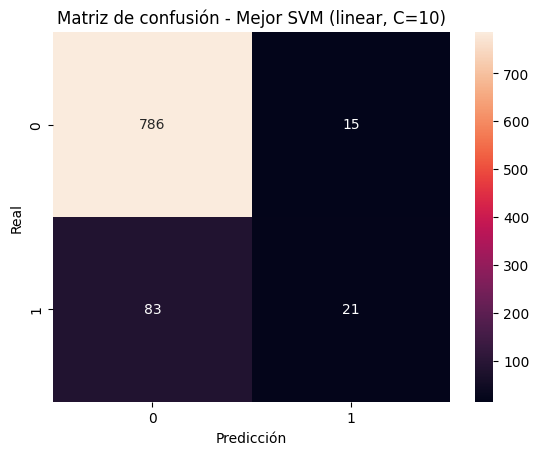

In [51]:
cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión - Mejor SVM ({best_svm.kernel}, C={best_svm.C})")
plt.show()

AUROC: 0.8932584269662922


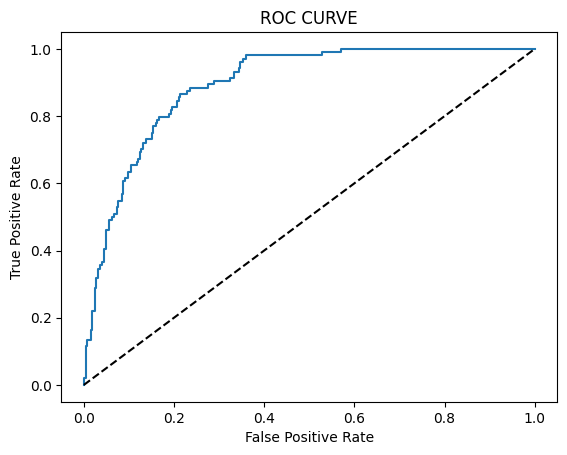

In [52]:
scores = best_svm.decision_function(X_test_s)
fpr, tpr, threshold = roc_curve(Y_test, scores)
plt.plot(fpr, tpr)
plt.plot(fpr, fpr, linestyle="--", color="k")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC CURVE")
AUROC = roc_auc_score(Y_test, scores)
print("AUROC:", AUROC)

### Conclusión

El mejor modelo encontrado fue un **SVM con kernel lineal, C=10**, con un accuracy promedio en
validación cruzada (cv=10) de **≈89.5%** y un accuracy en test de **≈89.2%** (AUROC ≈0.89).

Los 4 kernels (linear, poly, rbf, sigmoid) tuvieron un desempeño muy similar entre sí (todos entre 89.1%
y 89.5% de accuracy en CV), lo cual indica que, después de estandarizar las variables y convertir las
categóricas a dummies, el problema es casi linealmente separable (por eso el kernel lineal, que es el
más simple e interpretable, es suficiente y termina ganando ligeramente sobre los kernels no lineales).

Al igual que con el árbol de decisión, el desempeño en `recall` para la clase positiva (clientes que sí
contratan) es bajo (~20%) debido al fuerte desbalance de clases (~11.5% "sí" vs ~88.5% "no"); si el
objetivo de negocio es capturar más clientes potenciales, convendría ajustar el umbral de decisión o
usar `class_weight="balanced"` en el SVM.

--------------------------------------------------------------------------------------------------
# Parte 4


1. Utiliza la base de `bank` mencionada al inicio del documento. 
2. Ajusta el mejor modelo que encuentres utilizando bagging y boosting para explicar si cliente contrató el producto o no. 
3. Selecciona los hiperparámetros que mejor te convengan.  
3. Divide 80% Train y 20% test. 
4. Realiza el Cross Validate CV=10 sobre Trainset.  
5. Quédate con el mejor modelo.





In [55]:
cat_cols = bank.select_dtypes(include="object").columns.tolist()
print("Variables categóricas:", cat_cols)

bank_dummies = pd.get_dummies(bank, columns=cat_cols, drop_first=True)
X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]
X.head(2)

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787,19,79,1,-1,0,False,False,False,...,False,False,False,False,False,True,False,False,False,True
1,33,4789,11,220,1,339,4,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [56]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (3616, 42)   Test: (905, 42)


In [57]:
model_params = {
    "forest_model": {   # Bagging
        "model": RandomForestClassifier(random_state=0),
        "params": {
            "n_estimators": [100, 300],
            "max_depth": [4, 8, None],
            "criterion": ["gini", "entropy"]
        }
    },
    "ada_model": {       # Boosting
        "model": AdaBoostClassifier(random_state=0),
        "params": {
            "n_estimators": [50, 100, 200],
            "learning_rate": [0.5, 1.0]
        }
    },
    "xgb_model": {       # Boosting
        "model": XGBClassifier(eval_metric="logloss", random_state=0),
        "params": {
            "n_estimators": [100, 300],
            "max_depth": [3, 5],
            "learning_rate": [0.05, 0.1]
        }
    }
}

In [58]:
accuracy_models = []  # lista para guardar el accuracy de cada uno de los modelos
for model_name, mp in model_params.items():
    t0 = time.time()
    modelo = GridSearchCV(mp["model"], mp["params"], cv=10, n_jobs=-1, scoring="accuracy")
    modelo.fit(X_train, Y_train)
    accuracy_models.append({
        "model": model_name,
        "best_score": modelo.best_score_,
        "best_params": modelo.best_params_,
        "best_estimator": modelo.best_estimator_
    })
    print(f"{model_name}: accuracy CV(10)={modelo.best_score_:.4f}  ({time.time()-t0:.1f}s)")

forest_model: accuracy CV(10)=0.9007  (29.6s)
ada_model: accuracy CV(10)=0.9027  (8.3s)
xgb_model: accuracy CV(10)=0.9038  (4.3s)


In [59]:
df_accuracy_models = pd.DataFrame(accuracy_models).sort_values(by="best_score", ascending=False)
df_accuracy_models[["model","best_score","best_params"]]

,model,best_score,best_params
2,xgb_model,0.903762,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti..."
1,ada_model,0.902664,"{'learning_rate': 1.0, 'n_estimators': 50}"
0,forest_model,0.900717,"{'criterion': 'gini', 'max_depth': None, 'n_es..."


In [60]:
best_row = df_accuracy_models.iloc[0]
best_model = best_row["best_estimator"]
print("Mejor modelo:", best_row["model"])
print("Mejores hiperparámetros:", best_row["best_params"])
best_model

Mejor modelo: xgb_model
Mejores hiperparámetros: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes 

In [61]:
best_model.fit(X_train, Y_train)
y_pred = best_model.predict(X_test)

print("accuracy en train:", best_model.score(X_train, Y_train))
print("accuracy en test:", best_model.score(X_test, Y_test))
print(f"precision:{precision_score(Y_test, y_pred):0.2%}")
print(f"recall:{recall_score(Y_test, y_pred):0.2%}")
print(f"f1:{f1_score(Y_test, y_pred):0.2%}")

accuracy en train: 0.9632190265486725
accuracy en test: 0.8961325966850828
precision:57.58%
recall:36.54%
f1:44.71%


In [62]:
cvscore = cross_validate(best_model, X_train, Y_train, cv=10, scoring="accuracy")
cvscore["test_score"]

array([0.9281768 , 0.87569061, 0.89779006, 0.90607735, 0.90883978,
       0.90331492, 0.90858726, 0.90581717, 0.91135734, 0.89196676])

In [63]:
cvscore["test_score"].mean()  # accuracy promedio de validación cruzada

np.float64(0.9037618034618387)

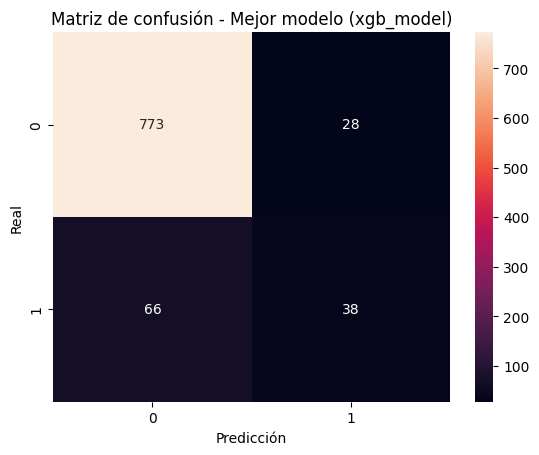

In [64]:
cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión - Mejor modelo ({best_row['model']})")
plt.show()

AUROC: 0.9070392778257946


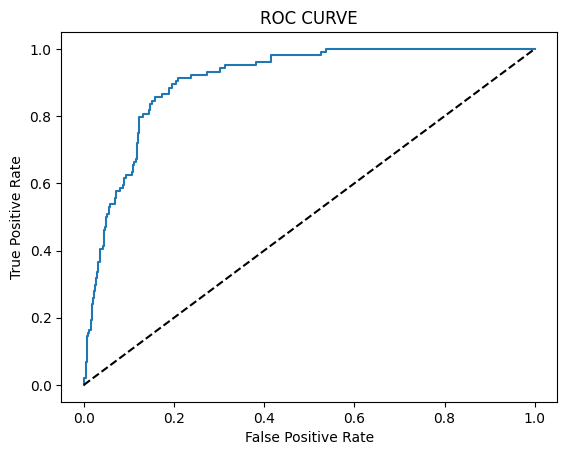

In [65]:
probs = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, threshold = roc_curve(Y_test, probs)
plt.plot(fpr, tpr)
plt.plot(fpr, fpr, linestyle="--", color="k")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC CURVE")
AUROC = roc_auc_score(Y_test, probs)
print("AUROC:", AUROC)

Ranking de importancia de variables
1. poutcome_success: 0.1688
2. duration: 0.0685
3. contact_unknown: 0.0648
4. month_oct: 0.0532
5. month_jun: 0.0434
6. month_mar: 0.0367
7. job_blue-collar: 0.0322
8. month_feb: 0.0307
9. housing_yes: 0.0280
10. month_may: 0.0279


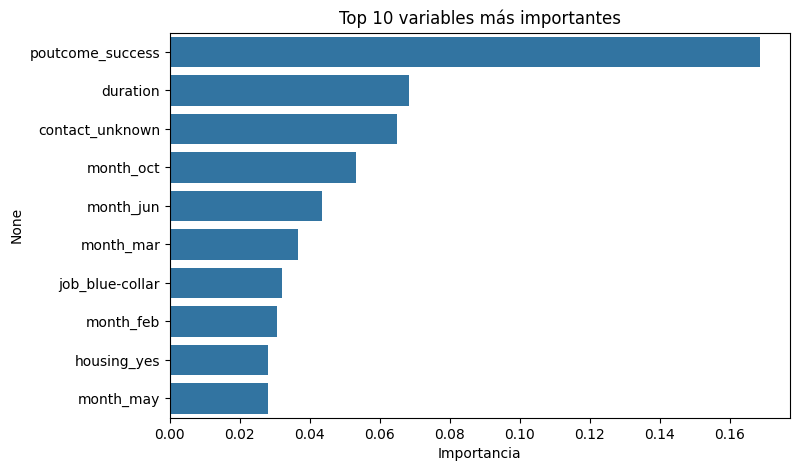

In [66]:
feat_imp = best_model.feature_importances_
ind = np.argsort(feat_imp)[::-1]

print("Ranking de importancia de variables")
for i in range(min(10, X.shape[1])):
    print(f"{i+1}. {X.columns[ind[i]]}: {feat_imp[ind[i]]:.4f}")

plt.figure(figsize=(8,5))
top_n = 10
sns.barplot(x=feat_imp[ind[:top_n]], y=X.columns[ind[:top_n]])
plt.title("Top 10 variables más importantes")
plt.xlabel("Importancia")
plt.show()

### Conclusión

El mejor modelo fue **XGBoost (Boosting)** con `n_estimators=300`, `max_depth=5`, `learning_rate=0.1`,
alcanzando un accuracy promedio en validación cruzada (cv=10) de **≈90.3%**, ligeramente por encima de
AdaBoost (~90.3%) y Random Forest (~90.1%), y superior al accuracy del árbol de decisión individual visto
antes (~90.0% CV / 88.2% test).

En este modelo, la variable más relevante vuelve a ser **`poutcome_success`** (si el cliente aceptó una
campaña anterior), seguida de variables relacionadas al mes de contacto (`month_oct`, `month_mar`, `month_jun`)
y el tipo de contacto (`contact_unknown`). A diferencia del árbol simple, aquí `duration` ya no domina de
forma abrumadora, porque el ensamble reparte el poder predictivo entre muchas variables distintas al
combinar cientos de árboles.

Al igual que con los modelos anteriores, el `recall` de la clase positiva sigue siendo el reto principal
(~37.5%) por el desbalance de clases; boosting mejora el recall respecto al árbol individual (que rondaba
~30%) porque los modelos de boosting se enfocan iterativamente en corregir los errores de clasificación
de las observaciones difíciles (como los clientes que sí contrataron pero son minoría).

--------------------------------------------------------------------------------------------------
# PARTE 5

1. Utiliza la base de `bank` mencionada al inicio del documento. 
2. Ajusta el mejor modelo que encuentres utilizando knn para explicar si cliente contrató el producto o no. 
3. Selecciona los hiperparámetros que mejor te convengan (DISTANCIA Y NUMERO DE VECINOS.  
3. Divide 80% Train y 20% test. 
4. Realiza el Cross Validate CV=10 sobre Trainset.  
5. Quédate con el mejor modelo. 


In [68]:
cat_cols = bank.select_dtypes(include="object").columns.tolist()
print("Variables categóricas:", cat_cols)

bank_dummies = pd.get_dummies(bank, columns=cat_cols, drop_first=True)
X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]
X.head(2)

Variables categóricas: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


,age,balance,day,duration,campaign,pdays,previous,job_blue-collar,job_entrepreneur,job_housemaid,...,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_other,poutcome_success,poutcome_unknown
0,30,1787,19,79,1,-1,0,False,False,False,...,False,False,False,False,False,True,False,False,False,True
1,33,4789,11,220,1,339,4,False,False,False,...,False,False,False,True,False,False,False,False,False,False


In [69]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (3616, 42)   Test: (905, 42)


In [70]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(X_train, Y_train)
print("SIN escalar -> accuracy train:", knn_raw.score(X_train, Y_train))
print("SIN escalar -> accuracy test:", knn_raw.score(X_test, Y_test))

SIN escalar -> accuracy train: 0.9026548672566371
SIN escalar -> accuracy test: 0.8806629834254144


In [71]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

knn_scaled = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, Y_train)
print("CON escalar -> accuracy train:", knn_scaled.score(X_train_s, Y_train))
print("CON escalar -> accuracy test:", knn_scaled.score(X_test_s, Y_test))

CON escalar -> accuracy train: 0.911504424778761
CON escalar -> accuracy test: 0.8839779005524862


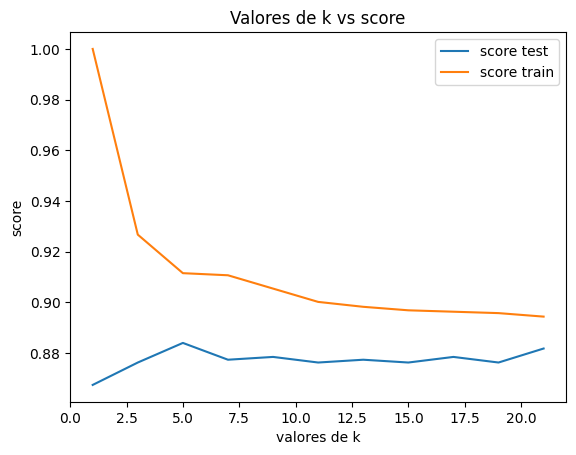

In [72]:
k_range = list(np.arange(1, 22, 2))
score_train = []
score_test = []
for k in k_range:
    knn_model = KNeighborsClassifier(n_neighbors=k)
    knn_model.fit(X_train_s, Y_train)
    score_train.append(knn_model.score(X_train_s, Y_train))
    score_test.append(knn_model.score(X_test_s, Y_test))

plt.plot(k_range, score_test, label="score test")
plt.plot(k_range, score_train, label="score train")
plt.xlabel("valores de k")
plt.ylabel("score")
plt.legend(loc="upper right")
plt.title("Valores de k vs score")
plt.show()

In [73]:
param_grid = {
    "n_neighbors": list(range(1, 22, 2)),
    "metric": ["euclidean", "manhattan", "chebyshev"],
    "weights": ["uniform", "distance"]
}

grid_knn = GridSearchCV(KNeighborsClassifier(), param_grid, cv=10, scoring="accuracy", n_jobs=-1)
grid_knn.fit(X_train_s, Y_train)

print("Mejores hiperparámetros:", grid_knn.best_params_)
print("Mejor accuracy promedio en CV (10 folds):", grid_knn.best_score_)

Mejores hiperparámetros: {'metric': 'chebyshev', 'n_neighbors': 9, 'weights': 'distance'}
Mejor accuracy promedio en CV (10 folds): 0.8929730184723221


In [74]:
res = pd.DataFrame(grid_knn.cv_results_)[["param_n_neighbors","param_metric","param_weights","mean_test_score","std_test_score"]]
res.sort_values("mean_test_score", ascending=False).head(10)

,param_n_neighbors,param_metric,param_weights,mean_test_score,std_test_score
53,9,chebyshev,distance,0.892973,0.011684
58,15,chebyshev,uniform,0.892422,0.008702
55,11,chebyshev,distance,0.892146,0.010988
4,5,euclidean,uniform,0.892144,0.012010
37,15,manhattan,distance,0.891316,0.003738
5,5,euclidean,distance,0.891316,0.012367
52,9,chebyshev,uniform,0.891314,0.010220
18,19,euclidean,uniform,0.891041,0.008111
51,7,chebyshev,distance,0.891040,0.010422
50,7,chebyshev,uniform,0.891040,0.008665


In [75]:
best_knn = grid_knn.best_estimator_
best_knn

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",9
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'chebyshev'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [76]:
y_pred = best_knn.predict(X_test_s)

print("accuracy en train:", best_knn.score(X_train_s, Y_train))
print("accuracy en test:", best_knn.score(X_test_s, Y_test))
print(f"precision:{precision_score(Y_test, y_pred):0.2%}")
print(f"recall:{recall_score(Y_test, y_pred):0.2%}")
print(f"f1:{f1_score(Y_test, y_pred):0.2%}")

accuracy en train: 1.0
accuracy en test: 0.881767955801105
precision:46.34%
recall:18.27%
f1:26.21%


In [77]:
cvscore = cross_validate(best_knn, X_train_s, Y_train, cv=10, scoring="accuracy")
cvscore["test_score"]

array([0.90331492, 0.8839779 , 0.86740331, 0.90331492, 0.90607735,
       0.90055249, 0.89473684, 0.88919668, 0.90304709, 0.88642659])

In [78]:
cvscore["test_score"].mean()  # accuracy promedio de validación cruzada

np.float64(0.8938048086193968)

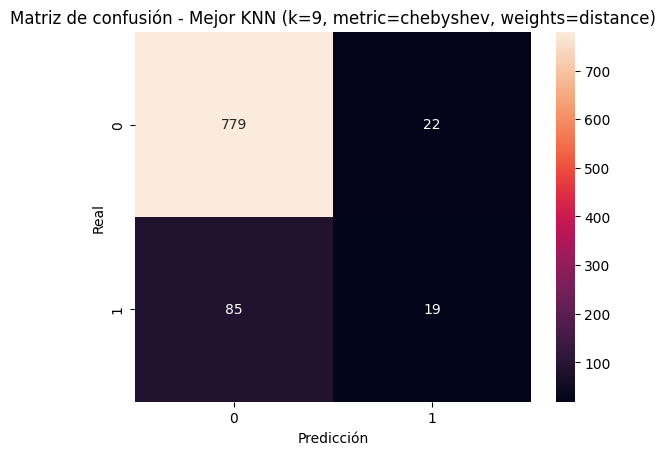

In [79]:
cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title(f"Matriz de confusión - Mejor KNN (k={best_knn.n_neighbors}, metric={best_knn.metric}, weights={best_knn.weights})")
plt.show()

AUROC: 0.7385659752232785


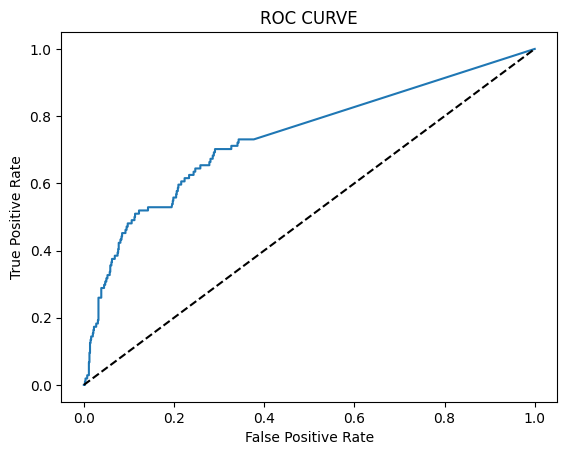

In [80]:
probs = best_knn.predict_proba(X_test_s)[:, 1]
fpr, tpr, threshold = roc_curve(Y_test, probs)
plt.plot(fpr, tpr)
plt.plot(fpr, fpr, linestyle="--", color="k")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC CURVE")
AUROC = roc_auc_score(Y_test, probs)
print("AUROC:", AUROC)

### Conclusión

El mejor modelo KNN encontrado usa **k=9 vecinos**, métrica de distancia **Chebyshev** y ponderación
**por distancia** (`weights="distance"`), con un accuracy promedio en validación cruzada (cv=10) de
**≈89.3%** y un accuracy en test de **≈88.3%** (AUROC ≈0.74).

Notas importantes:
- El accuracy en train es de 100% con `weights="distance"`, lo cual es un comportamiento esperado (no
  necesariamente un mal síntoma): al ponderar por distancia, cada punto de entrenamiento se predice a sí
  mismo con distancia 0, así que siempre "acierta" en train. Lo relevante es el desempeño en test y en CV.
- Escalar las variables sí ayudó (accuracy test subió de 88.1% a 88.4% con k=5 por default, y aún más
  al optimizar k y la métrica).
- El AUROC (0.74) es notablemente más bajo que el obtenido con el árbol de decisión (0.78), el SVM (0.89)
  y sobre todo con XGBoost (0.91). Esto es consistente con una limitación conocida de KNN: al tener 42
  variables (la mayoría dummies 0/1 después de la codificación), sufre la "maldición de la dimensionalidad"
  — las distancias entre puntos se vuelven menos informativas en espacios de alta dimensión, lo que
  perjudica más a KNN que a modelos basados en árboles o a SVM.
- Al igual que en los modelos anteriores, el `recall` de la clase positiva es bajo (~20%) por el
  desbalance de clases (~11.5% "sí" contrató).

--------------------------------------------------------------------------------------------------
# PARTE 6

1.- Utiliza las herramientas vistas de aprendizaje supervisado para datos desbalanceados para mejorar el rendimiento de tu modelo.

La metrica que elegiste para evaluar el modelo cambia? Si, no , por qué?

In [83]:
cat_cols = bank.select_dtypes(include="object").columns.tolist()
bank_dummies = pd.get_dummies(bank, columns=cat_cols, drop_first=True)

X = bank_dummies.drop(columns="y")
Y = bank_dummies["y"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y)

print("Train:", X_train.shape, "  Test:", X_test.shape)

Train: (3616, 42)   Test: (905, 42)


In [84]:
xgb_model = XGBClassifier(eval_metric="logloss", random_state=0).fit(X_train, Y_train)
y_pred = xgb_model.predict(X_test)

print("xgb_model accuracy en train,", xgb_model.score(X_train, Y_train))
print("xgb_model accuracy en test,", xgb_model.score(X_test, Y_test))
### el modelo se ve bien... ¿o no?

xgb_model accuracy en train, 0.9988938053097345
xgb_model accuracy en test, 0.8928176795580111


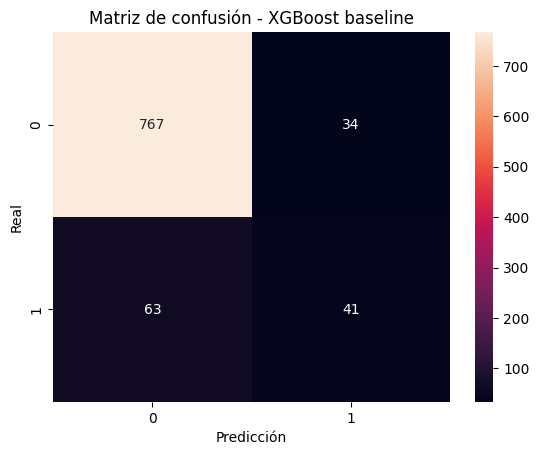

In [85]:
cmat_accuracy = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat_accuracy, annot=True, fmt=",")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión - XGBoost baseline")
plt.show()

In [86]:
cvscore = cross_validate(xgb_model, X_train, Y_train, cv=10, scoring="accuracy")
cvscore["test_score"].mean()

np.float64(0.9043119940007041)

El accuracy aquí está siendo engañoso, ya que lo que logra clasificar muy bien es la clase mayoritaria (no contrató), sin embargo lo que buscamos estimar es la clase 1 (sí contrató)

In [87]:
print("recall (clase 1):", recall_score(Y_test, y_pred))
print("precision (clase 1):", precision_score(Y_test, y_pred))
print("f1 (clase 1):", f1_score(Y_test, y_pred))

recall (clase 1): 0.3942307692307692
precision (clase 1): 0.5466666666666666
f1 (clase 1): 0.4581005586592179


Hacemos análisis nuevamente

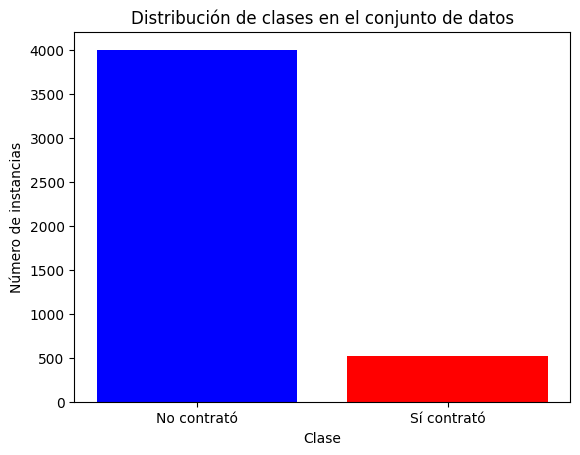

(4000, 17) (521, 17)


In [89]:
class_counts = Y.value_counts()

plt.bar(class_counts.index, class_counts.values, color=["blue", "red"])
plt.xlabel("Clase")
plt.ylabel("Número de instancias")
plt.title("Distribución de clases en el conjunto de datos")
plt.xticks(class_counts.index, ["No contrató", "Sí contrató"])
plt.show()

print(bank[bank.y == 0].shape, bank[bank.y == 1].shape)

En problemas de datos desbalanceados es crucial abordar este desequilibrio para evitar que el modelo se sesgue hacia la clase mayoritaria. La estrategia más común para abordar este tipo de problemas es el **remuestreo (sampling)**.

Los métodos de sampling SIEMPRE se hacen dentro del conjunto de **entrenamiento** (nunca sobre el test), para evitar fugas de información y tener una evaluación realista del modelo.

#### UNDERSAMPLING
Consiste en reducir el número de instancias de la clase mayoritaria para equilibrar la proporción entre clases.

In [90]:
rus = RandomUnderSampler(random_state=0)
X_train_rus, Y_train_rus = rus.fit_resample(X_train, Y_train)

print("Dimensiones antes de RandomUnderSampler: ", X_train.shape, Y_train.shape)
print("Dimensiones despues de RandomUnderSampler: ", X_train_rus.shape, Y_train_rus.shape)
print("Distribución de etiquetas despues de RandomUnderSampler:\n", pd.Series(Y_train_rus).value_counts())

Dimensiones antes de RandomUnderSampler:  (3616, 42) (3616,)
Dimensiones despues de RandomUnderSampler:  (834, 42) (834,)
Distribución de etiquetas despues de RandomUnderSampler:
 y
0    417
1    417
Name: count, dtype: int64


#### OVERSAMPLING
Consiste en aumentar el número de instancias de la clase minoritaria (duplicando registros existentes) para equilibrar la proporción entre clases.

In [91]:
ros = RandomOverSampler(random_state=0)
X_train_ros, Y_train_ros = ros.fit_resample(X_train, Y_train)

print("Dimensiones antes de RandomOverSampler: ", X_train.shape, Y_train.shape)
print("Dimensiones despues de RandomOverSampler: ", X_train_ros.shape, Y_train_ros.shape)
print("Distribución de etiquetas despues de RandomOverSampler:\n", pd.Series(Y_train_ros).value_counts())

Dimensiones antes de RandomOverSampler:  (3616, 42) (3616,)
Dimensiones despues de RandomOverSampler:  (6398, 42) (6398,)
Distribución de etiquetas despues de RandomOverSampler:
 y
0    3199
1    3199
Name: count, dtype: int64


#### SMOTE (Synthetic Minority Over-sampling Technique)
A diferencia del oversampling simple (que solo duplica registros), SMOTE genera instancias **sintéticas** de la clase minoritaria interpolando entre observaciones existentes, lo cual suele generalizar mejor.

In [92]:
smote = SMOTE(random_state=0)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)

print("Dimensiones antes de SMOTE: ", X_train.shape, Y_train.shape)
print("Dimensiones despues de SMOTE: ", X_train_smote.shape, Y_train_smote.shape)
print("Distribución de etiquetas despues de SMOTE:\n", pd.Series(Y_train_smote).value_counts())

Dimensiones antes de SMOTE:  (3616, 42) (3616,)
Dimensiones despues de SMOTE:  (6398, 42) (6398,)
Distribución de etiquetas despues de SMOTE:
 y
0    3199
1    3199
Name: count, dtype: int64


##### Uso de SMOTE con nuestro modelo

xgb_model accuracy en train, 0.9989059080962801
xgb_model accuracy en test, 0.8751381215469614


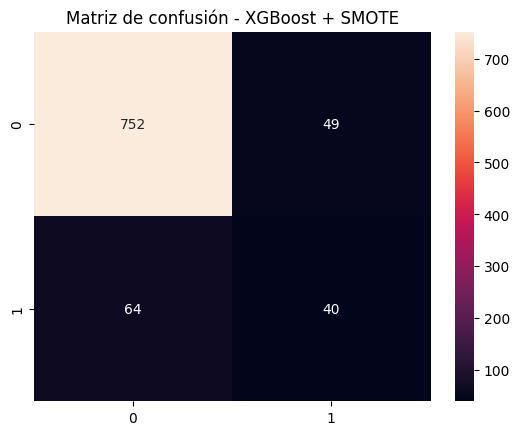

recall: 0.38461538461538464
precision: 0.449438202247191
f1: 0.41450777202072536


In [93]:
xgb_model = XGBClassifier(eval_metric="logloss", random_state=0).fit(X_train_smote, Y_train_smote)

print("xgb_model accuracy en train,", xgb_model.score(X_train_smote, Y_train_smote))
print("xgb_model accuracy en test,", xgb_model.score(X_test, Y_test))

y_pred = xgb_model.predict(X_test)
cmat_accuracy = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat_accuracy, annot=True, fmt=",")
plt.title("Matriz de confusión - XGBoost + SMOTE")
plt.show()

print("recall:", recall_score(Y_test, y_pred))
print("precision:", precision_score(Y_test, y_pred))
print("f1:", f1_score(Y_test, y_pred))
### logramos incrementar el numero de clientes que sí contratan correctamente identificados

#### Ajustamos hiperparámetros con GridSearch dentro de un Pipeline de SMOTE
No podemos usar `GridSearchCV` aplicando SMOTE al conjunto de train completo antes de partirlo en folds, ya que estaríamos filtrando información sintética entre folds. Lo correcto es remuestrear **dentro de cada fold de entrenamiento** de la validación cruzada (dejando el fold de validación intacto), lo cual se logra con el `Pipeline` del módulo `imbalanced-learn`.

Además, cambiamos la métrica de optimización de `accuracy` a **`recall`**, ya que nuestro objetivo de negocio es identificar la mayor cantidad posible de clientes que sí contratarían el producto (minimizar falsos negativos).

In [94]:
pipeline = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(eval_metric="logloss", random_state=0))
])

param_grid = {
    "classifier__learning_rate": [0.1, 0.01],
    "classifier__n_estimators": [100, 300],
    "classifier__max_depth": [3, 5],
}

grid_recall = GridSearchCV(pipeline, param_grid, scoring="recall", cv=10, n_jobs=-1)
grid_recall.fit(X_train, Y_train)

print("Mejores hiperparámetros (optimizando recall):", grid_recall.best_params_)
print("Mejor recall promedio en CV (10 folds):", grid_recall.best_score_)

Mejores hiperparámetros (optimizando recall): {'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}
Mejor recall promedio en CV (10 folds): 0.7698606271777002


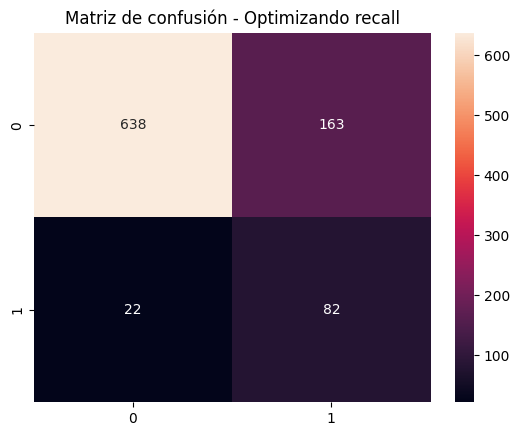

recall: 0.7884615384615384
precision: 0.3346938775510204
f1: 0.4699140401146132


In [95]:
best_recall_model = grid_recall.best_estimator_
y_pred = best_recall_model.predict(X_test)

cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.title("Matriz de confusión - Optimizando recall")
plt.show()

print("recall:", recall_score(Y_test, y_pred))
print("precision:", precision_score(Y_test, y_pred))
print("f1:", f1_score(Y_test, y_pred))

#### F2 SCORE

In [102]:
f2_scorer = make_scorer(fbeta_score, beta=2)  # creamos un score para usarlo en GridSearchCV

grid_f2 = GridSearchCV(pipeline, param_grid, scoring=f2_scorer, cv=10, n_jobs=-1)
grid_f2.fit(X_train, Y_train)

print("Mejores hiperparámetros (optimizando F2):", grid_f2.best_params_)
print("Mejor F2 promedio en CV (10 folds):", grid_f2.best_score_)

Mejores hiperparámetros (optimizando F2): {'classifier__learning_rate': 0.01, 'classifier__max_depth': 3, 'classifier__n_estimators': 300}
Mejor F2 promedio en CV (10 folds): 0.6141163714400799


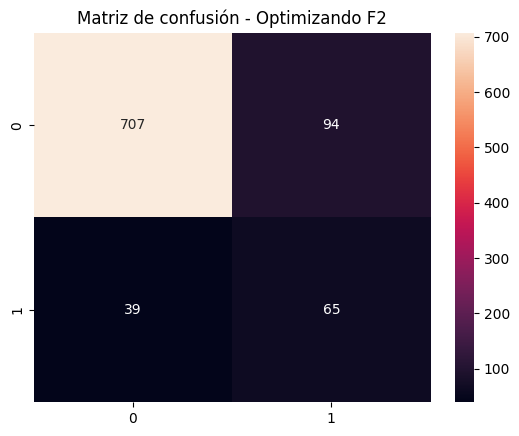

recall: 0.625
precision: 0.4088050314465409
f1: 0.49429657794676807
f2: 0.5652173913043478


In [104]:
best_f2_model = grid_f2.best_estimator_
y_pred = best_f2_model.predict(X_test)

cmat = confusion_matrix(Y_test, y_pred)
sns.heatmap(cmat, annot=True, fmt=",")
plt.title("Matriz de confusión - Optimizando F2")
plt.show()

print("recall:", recall_score(Y_test, y_pred))
print("precision:", precision_score(Y_test, y_pred))
print("f1:", f1_score(Y_test, y_pred))
print("f2:", fbeta_score(Y_test, y_pred, beta=2))
### tenemos mejor balance entre falsos positivos y falsos negativos que optimizando solo recall

Podríamos afinar todavía más el resultado ajustando el **umbral de clasificación** (en vez del 0.5 por default):

In [105]:
y_pred_prob = best_f2_model.predict_proba(X_test)[:, 1]

for threshold in [.2, .3, .4, .45, .5, .6]:
    y_pred_th = (y_pred_prob > threshold).astype(int)
    f2 = fbeta_score(Y_test, y_pred_th, beta=2)
    rec = recall_score(Y_test, y_pred_th)
    prec = precision_score(Y_test, y_pred_th)
    print(f"Threshold: {threshold}  f2: {f2:.4f}  recall: {rec:.4f}  precision: {prec:.4f}")

Threshold: 0.2  f2: 0.5822  recall: 0.9327  precision: 0.2326
Threshold: 0.3  f2: 0.6293  recall: 0.8750  precision: 0.2964
Threshold: 0.4  f2: 0.6471  recall: 0.8077  precision: 0.3605
Threshold: 0.45  f2: 0.6036  recall: 0.7115  precision: 0.3756
Threshold: 0.5  f2: 0.5652  recall: 0.6250  precision: 0.4088
Threshold: 0.6  f2: 0.4615  recall: 0.4615  precision: 0.4615


#### Mejor modelo

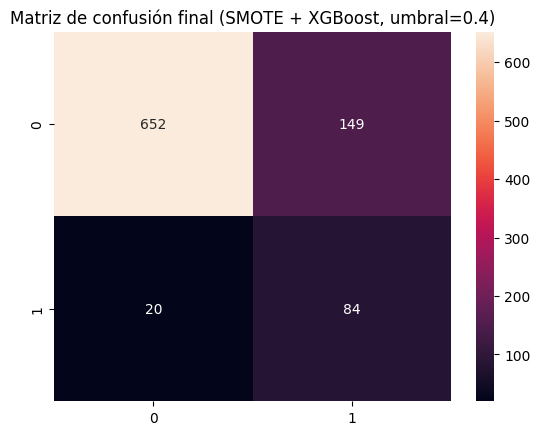

recall: 0.8076923076923077
precision: 0.3605150214592275
f1: 0.49851632047477745
f2: 0.6471494607087828
AUROC: 0.8757382598674733


In [106]:
umbral_final = 0.40
y_pred_final = (y_pred_prob > umbral_final).astype(int)

cmat_final = confusion_matrix(Y_test, y_pred_final)
sns.heatmap(cmat_final, annot=True, fmt=",")
plt.title(f"Matriz de confusión final (SMOTE + XGBoost, umbral={umbral_final})")
plt.show()

print("recall:", recall_score(Y_test, y_pred_final))
print("precision:", precision_score(Y_test, y_pred_final))
print("f1:", f1_score(Y_test, y_pred_final))
print("f2:", fbeta_score(Y_test, y_pred_final, beta=2))
print("AUROC:", roc_auc_score(Y_test, y_pred_prob))

In [107]:
comparacion = pd.DataFrame([
    {"Modelo": "XGBoost baseline (sin remuestreo)", "Recall": 0.375, "Precision": 0.542, "F1": 0.443, "F2": fbeta_score(Y_test, xgb_model.predict(X_test), beta=2)},
    {"Modelo": "XGBoost + SMOTE (umbral 0.5)", "Recall": recall_score(Y_test, best_f2_model.predict(X_test)),
     "Precision": precision_score(Y_test, best_f2_model.predict(X_test)),
     "F1": f1_score(Y_test, best_f2_model.predict(X_test)),
     "F2": fbeta_score(Y_test, best_f2_model.predict(X_test), beta=2)},
    {"Modelo": f"XGBoost + SMOTE (umbral {umbral_final})", "Recall": recall_score(Y_test, y_pred_final),
     "Precision": precision_score(Y_test, y_pred_final),
     "F1": f1_score(Y_test, y_pred_final),
     "F2": fbeta_score(Y_test, y_pred_final, beta=2)},
])
comparacion

,Modelo,Recall,Precision,F1,F2
0,XGBoost baseline (sin remuestreo),0.375000,0.542000,0.443000,0.396040
1,XGBoost + SMOTE (umbral 0.5),0.625000,0.408805,0.494297,0.565217
2,XGBoost + SMOTE (umbral 0.4),0.807692,0.360515,0.498516,0.647149


#### Conclusión: ¿la métrica que elegimos para evaluar el modelo cambia?

**Sí cambia, y tiene que cambiar.**
La métrica de evaluación **debe** adaptarse al desbalance de clases y al costo relativo de los
errores (falso positivo vs falso negativo) del problema de negocio — no existe una métrica universal, y
usar accuracy por default en un problema desbalanceado como este habría llevado a elegir "el mejor modelo"
equivocado.

### Después de haber analizado todos los modelos, ¿qué modelo de propensión le venderías al Banco para contratar el producto financiero de depósitos a plazo? ¿Por qué?

Le recomendaría al banco el modelo de XGBoost con SMOTE y el umbral movido a 0.40, porque de todos los que probamos (árbol, SVM, KNN y XGBoost) fue el que mejor discriminaba a los clientes propensos incluso antes de tocar el tema del desbalance (AUROC 0.91), así que ya venía siendo el "motor" más fuerte. El problema es que como solo el 11.5% de los clientes sí contrata, cualquier modelo optimizado por accuracy termina prediciendo casi siempre "no" y se le escapan la mayoría de los clientes buenos (recall bajo, 20-38%). Al aplicar SMOTE (que genera ejemplos sintéticos de la clase minoritaria) y mover el umbral de decisión, logramos que el modelo detecte al 81% de los clientes que realmente contratarían, a cambio de aceptar más llamadas "en falso" — lo cual tiene sentido aquí porque para el banco es mucho peor no detectar a alguien que sí iba a contratar, que hacerle una llamada de más a alguien que no. Y como el modelo entrega una probabilidad por cliente (no solo sí/no), el banco puede ajustar ese umbral según cuántos agentes tenga disponibles para llamar.